# Tahoe-100M: drug wells (context for the DMSO floor) and a row test

Two questions, using more wells than the DMSO-only run (`tahoe_dmso_check.ipynb`, whose cache is reused):

1. **How large is the DMSO-vs-DMSO difference compared with a drug response?**
   Eight random wells at the highest dose on every plate (112 wells). For each plate and cell line we compare
   the size of a drug response with the size of the difference between the two DMSO wells (as in Parse, where the
   floor was about 12% of a strong cytokine response).
2. **Do responses carry the signal of their plate row?** (as in OP3)
   All 96 wells of four plates. The first barcode round gives the well number (1 to 96; the DMSO wells are 95 and 96,
   i.e. H11 and H12), so each well has a row. Different plates hold different drugs, so a row signature that recurs
   across plates must come from position, not from the drugs.

To keep the download small, cells are read from a random fraction of the files (`FILE_FRACTION`); each well's cells
are spread over many files, so this keeps about that fraction of every well's cells. Results are saved after every
50 files, so cells can be stopped and run again. Log in once with `huggingface-cli login`.

## 1. Setup

In [1]:
import os, time, json, pickle
from datetime import datetime
import numpy as np, pandas as pd
import pyarrow as pa, pyarrow.parquet as pq, pyarrow.compute as pc
import scipy.sparse as sp
from huggingface_hub import HfFileSystem, list_repo_files

REPO = "tahoebio/Tahoe-100M"
OUT = "cache"; os.makedirs(OUT, exist_ok=True)
SEED = 0
FILE_FRACTION = 0.35            # fraction of files read for the new wells
N_DRUG_WELLS_PER_PLATE = 8      # question 1
ROW_TEST_PLATES = ["plate1", "plate2", "plate3", "plate4"]   # question 2; plates 1-3 share compounds (dose series); only pairs with plate4 are tested

fs = HfFileSystem()
files = list_repo_files(REPO, repo_type="dataset")
data_files = sorted(f for f in files if f.startswith("data/") and f.endswith(".parquet"))
sm = pd.read_parquet(f"hf://datasets/{REPO}/metadata/sample_metadata.parquet", filesystem=fs)
sm["dose"] = sm["drugname_drugconc"].astype(str).str.extract(r",\s*([0-9.]+),")[0].astype(float)
PLATE = dict(zip(sm["sample"], sm["plate"])); DRUG = dict(zip(sm["sample"], sm["drug"]))

def with_retry(fn, *a, tries=8):
    for t in range(tries):
        try:
            return fn(*a)
        except Exception as e:
            if "429" in str(e) or "Too Many Requests" in str(e):
                wait = 60 * (t + 1); print(f"rate limit, waiting {wait} s", flush=True); time.sleep(wait)
            else:
                raise
    raise RuntimeError("too many retries")

## 2. Choose the wells

In [2]:
rng = np.random.default_rng(SEED)
drugs = sm[(sm.drug != "DMSO_TF") & ~sm.drug.str.contains("DMSO", case=False)]
top = drugs[drugs.dose == drugs.groupby("drug").dose.transform("max")]      # highest dose of each drug
CONTEXT = sorted(s for p, g in drugs.groupby("plate")
                 for s in rng.choice(g["sample"].values, min(N_DRUG_WELLS_PER_PLATE, len(g)), replace=False))
ROWTEST = sorted(sm.loc[sm.plate.isin(ROW_TEST_PLATES) & (sm.drug != "DMSO_TF"), "sample"])
WANT = sorted(set(CONTEXT) | set(ROWTEST))
print(len(CONTEXT), "context wells;", len(ROWTEST), "row-test wells;", len(WANT), "wells to read")

112 context wells; 376 row-test wells; 456 wells to read


## 3. Block ranges of every file (footer only, saved once)
Same idea as in `tahoe_dmso_check`: cells are sorted by well inside a file, so the footer tells which of the 29 blocks hold a well. This pass stores the ranges of all blocks, so any set of wells can be selected later without reading footers again (about 30 minutes).

In [3]:
F_RANGES = f"{OUT}/tahoe_block_ranges.json"

def block_ranges(f):
    with fs.open(f"datasets/{REPO}/{f}", block_size=2**20) as fh:
        md_ = pq.ParquetFile(fh).metadata
        i = md_.schema.names.index("sample")
        out = []
        for rg in range(md_.num_row_groups):
            st = md_.row_group(rg).column(i).statistics
            out.append([st.min, st.max] if st is not None and st.has_min_max else [None, None])
        return out

ranges = json.load(open(F_RANGES)) if os.path.exists(F_RANGES) else {}
print("start:", datetime.now().strftime("%H:%M:%S"))
for k, f in enumerate(data_files):
    if f in ranges:
        continue
    ranges[f] = with_retry(block_ranges, f); time.sleep(0.15)
    if k % 200 == 0:
        json.dump(ranges, open(F_RANGES, "w")); print(f"{k}/{len(data_files)}", datetime.now().strftime("%H:%M:%S"), flush=True)
json.dump(ranges, open(F_RANGES, "w"))

start: 18:00:47


## 4. Read the blocks of the chosen wells (from a random fraction of the files)
Raw counts; the first entry of each cell (gene token 1, value -2) is a special token and is dropped. Cells are split into two random halves per well and cell line.

In [4]:
F_STATE = f"{OUT}/tahoe_more_state.pkl"
COLS = ["genes", "expressions", "sample", "cell_line_id", "BARCODE_SUB_LIB_ID"]
want_set = set(WANT)
file_rng = np.random.default_rng(SEED + 1)
use_files = [f for f in data_files if file_rng.random() < FILE_FRACTION]
JOBS = {}
for f in use_files:
    bl = [i for i, (lo, hi) in enumerate(ranges[f]) if lo is None or any(lo <= s <= hi for s in WANT)]
    if bl:
        JOBS[f] = bl
print(len(JOBS), "files,", sum(map(len, JOBS.values())), "blocks")

if os.path.exists(F_STATE):
    sums, ncell, well_no, done = pickle.load(open(F_STATE, "rb"))
else:
    sums, ncell, well_no, done = {}, {}, {}, set()
rng = np.random.default_rng(SEED + 2 + len(done))

def read_blocks(f, blocks):
    with fs.open(f"datasets/{REPO}/{f}", block_size=2**22) as fh:
        t = pq.ParquetFile(fh).read_row_groups(blocks, columns=COLS)
    return t.filter(pc.is_in(t.column("sample"), value_set=pa.array(WANT))).to_pandas()

print("start:", datetime.now().strftime("%H:%M:%S"))
for f, blocks in JOBS.items():
    if f in done:
        continue
    df = with_retry(read_blocks, f, blocks)
    if len(df):
        half = np.where(rng.random(len(df)) < 0.5, "A", "B")
        for (smp, cl, h), idx in df.groupby([df["sample"], df["cell_line_id"], half]).indices.items():
            g = np.concatenate(df["genes"].values[idx]); x = np.concatenate(df["expressions"].values[idx])
            keep = (g != 1) & (x >= 0)
            row = sp.csr_matrix((x[keep].astype(np.float32), (np.zeros(keep.sum(), int), g[keep])), shape=(1, 70000))
            key = (PLATE[smp], smp, cl, h)
            sums[key] = sums[key] + row if key in sums else row
            ncell[key] = ncell.get(key, 0) + len(idx)
        for smp, bc in zip(df["sample"], df["BARCODE_SUB_LIB_ID"]):
            well_no.setdefault(smp, set()).add(int(bc.split("_")[0]))
    done.add(f); time.sleep(0.3)
    if len(done) % 50 == 0:
        pickle.dump((sums, ncell, well_no, done), open(F_STATE, "wb"))
        print(f"{len(done)}/{len(JOBS)} files, {sum(ncell.values())} cells", datetime.now().strftime("%H:%M:%S"), flush=True)
pickle.dump((sums, ncell, well_no, done), open(F_STATE, "wb"))
print("done:", sum(ncell.values()), "cells")

1203 files, 14735 blocks
start: 18:00:56
done: 11386018 cells


## 5. Combine with the DMSO pseudobulks

In [5]:
# DMSO wells (from tahoe_dmso_check) + new wells, on one gene axis (token ids)
Md = sp.load_npz(f"{OUT}/tahoe_dmso_pb.npz").tocsr(); tok_d = np.load(f"{OUT}/tahoe_dmso_gene_tokens.npy")
meta_d = pd.read_csv(f"{OUT}/tahoe_dmso_meta.csv")
keys = sorted(sums); Mn = sp.vstack([sums[k] for k in keys]).tocsr()
Mn = Mn[:, tok_d]                                   # same genes as the DMSO matrix
meta_n = pd.DataFrame(keys, columns=["plate", "sample", "cell_line", "half"]); meta_n["n_cells"] = [ncell[k] for k in keys]
MM = sp.vstack([Md, Mn]).tocsr().astype(np.float64)
META = pd.concat([meta_d, meta_n], ignore_index=True)
WELL = {s: min(v) for s, v in well_no.items()}; WELL.update({s: (95 if i == 0 else 96) for p, g in meta_d.groupby("plate")
                                                             for i, s in enumerate(sorted(g["sample"].unique()))})
META["well_no"] = META["sample"].map(WELL); META["row"] = (META.well_no - 1) // 12; META["col"] = (META.well_no - 1) % 12 + 1
META["drug"] = META["sample"].map(DRUG)
print(META.groupby("sample").n_cells.sum().describe().round(0).to_string())
print("wells with more than one barcode id:", sum(len(v) > 1 for v in well_no.values()))

GENES = np.argsort(-np.asarray(MM.sum(0)).ravel())[:2000]
IX = {(r.sample, r.cell_line, r.half): i for i, r in enumerate(META.itertuples())}
NC = {(r.sample, r.cell_line, r.half): r.n_cells for r in META.itertuples()}
def lc(i): x = MM[i].toarray().ravel(); return np.log1p(x / max(x.sum(), 1) * 1e6)[GENES]
def halves(s, c, min_cells=50):
    if NC.get((s, c, "A"), 0) < min_cells or NC.get((s, c, "B"), 0) < min_cells:
        return None
    return lc(IX[(s, c, "A")]), lc(IX[(s, c, "B")])
DMSO_OF = {p: sorted(g["sample"].unique()) for p, g in meta_d.groupby("plate")}

count       523.0
mean      25988.0
std       17955.0
min          17.0
25%       16288.0
50%       23429.0
75%       31201.0
max      141054.0
wells with more than one barcode id: 0


## 6. Question 1: DMSO-vs-DMSO difference relative to drug responses
Cross-half sizes (sampling noise cancels between independent halves):
- floor = (w1A - w2A)·(w1B - w2B) / 2, the size attributable to one DMSO well beyond sampling noise;
- drug = (dA - mA)·(dB - mB), with m the mean of the two DMSO wells of the plate.
Ratio = floor / drug, per plate, cell line and drug well.

In [6]:
rows = []
for s in CONTEXT:
    p = PLATE[s]; w1, w2 = DMSO_OF[p]
    for c in META.cell_line.unique():
        d, a, b = halves(s, c), halves(w1, c), halves(w2, c)
        if d is None or a is None or b is None:
            continue
        floor = (a[0] - b[0]) @ (a[1] - b[1]) / 2
        drug = (d[0] - (a[0] + b[0]) / 2) @ (d[1] - (a[1] + b[1]) / 2)
        rows.append(dict(plate=p, sample=s, drug=DRUG[s], dose=sm.set_index("sample").dose[s], cell_line=c, floor=floor, drug_size=drug))
CTX = pd.DataFrame(rows)
CTX.to_csv(f"{OUT}/tahoe_floor_vs_drugs.csv", index=False)
strong = CTX.drug_size >= CTX.drug_size.quantile(0.9)
print("floor / drug response, median over all drug wells and cell lines: %.2f" % (CTX.floor / CTX.drug_size).median())
print("floor / drug response, strongest 10%% of responses:             %.2f" % (CTX.floor[strong] / CTX.drug_size[strong]).median())
print("share of drug responses smaller than the DMSO floor: %.0f%%" % (100 * (CTX.drug_size < CTX.floor).mean()))
print(CTX.groupby("drug").drug_size.median().sort_values(ascending=False).head(10).round(1).to_string())

floor / drug response, median over all drug wells and cell lines: 0.20
floor / drug response, strongest 10% of responses:             0.05
share of drug responses smaller than the DMSO floor: 0%
drug
Digitoxin                         770.7
Bortezomib                        565.8
Epirubicin (hydrochloride)        310.4
Mitoxantrone (dihydrochloride)    265.9
Binimetinib                       215.2
ULK-101                           164.3
Dabrafenib                        163.5
LY-2584702 (tosylate salt)        150.7
Ouabain (Octahydrate)             138.1
Abemaciclib                       128.1


## 7. Question 2: do responses carry the signal of their plate row?
Response of a well = its log CPM minus the mean of the plate's two DMSO wells. Row effect = mean response of the wells of a row minus the mean of all wells of the plate (DMSO wells excluded). Because different plates hold different drugs, a row effect that agrees between plates comes from position. Same-row correlation between plates is compared with different-row correlation; p from permuting row labels.

In [7]:
from itertools import combinations
from scipy.stats import pearsonr
N_PERM = 1000
lines = sorted(META.cell_line.unique())
ROWEFF = {}                          # (plate, cell line) -> {row: vector}
for p in ROW_TEST_PLATES:
    w1, w2 = DMSO_OF[p]
    wells = META[(META.plate == p) & ~META["sample"].isin([w1, w2])][["sample", "row"]].drop_duplicates()
    for c in lines:
        a, b = halves(w1, c), halves(w2, c)
        if a is None or b is None:
            continue
        ref = (a[0] + a[1] + b[0] + b[1]) / 4
        R = {}
        for s, r in zip(wells["sample"], wells.row):
            h = halves(s, c, min_cells=25)
            if h is not None:
                R.setdefault(r, []).append((h[0] + h[1]) / 2 - ref)
        if len(R) < 6:
            continue
        allm = np.mean([v for vs in R.values() for v in vs], 0)
        ROWEFF[(p, c)] = {r: np.mean(vs, 0) - allm for r, vs in R.items() if len(vs) >= 3}

rng = np.random.default_rng(SEED)
rows = []
for c in lines:
    ps = [p for p in ROW_TEST_PLATES if (p, c) in ROWEFF]
    for p, q in combinations(ps, 2):
        if set(sm.drug[sm.plate == p]) & set(sm.drug[sm.plate == q]) - {"DMSO_TF"} and \
           len(set(sm.drug[sm.plate == p]) & set(sm.drug[sm.plate == q])) > 10:
            continue                     # same compounds on both plates (dose series): position and compound not separable
        E, F = ROWEFF[(p, c)], ROWEFF[(q, c)]
        common = sorted(set(E) & set(F))
        if len(common) < 6:
            continue
        C = np.array([[pearsonr(E[r], F[s])[0] for s in common] for r in common])
        same, other = np.mean(np.diag(C)), C[~np.eye(len(common), dtype=bool)].mean()
        null = [np.mean(C[np.arange(len(common)), rng.permutation(len(common))]) for _ in range(N_PERM)]
        rows.append(dict(cell_line=c, plates=f"{p}-{q}", same_row=same, other_rows=other,
                         p=(1 + np.sum(np.array(null) >= same)) / (N_PERM + 1)))
ROWS = pd.DataFrame(rows)
ROWS.to_csv(f"{OUT}/tahoe_row_test.csv", index=False)
print("same row: median %.3f; other rows: median %.3f; tests with p < 0.05: %d of %d" %
      (ROWS.same_row.median(), ROWS.other_rows.median(), (ROWS.p < 0.05).sum(), len(ROWS)))
print(ROWS.groupby("plates")[["same_row", "other_rows"]].median().round(3).to_string())

same row: median 0.111; other rows: median -0.016; tests with p < 0.05: 50 of 136
               same_row  other_rows
plates                             
plate1-plate4     0.267      -0.038
plate2-plate4     0.117      -0.017
plate3-plate4     0.060      -0.005


## 8. Figure S8 (paper style)
Reads only the csv files in `cache/`, so it also works without sections 3 to 7 (panel D is then marked missing). Replaces the figure cell of `tahoe_dmso_tests.ipynb`.

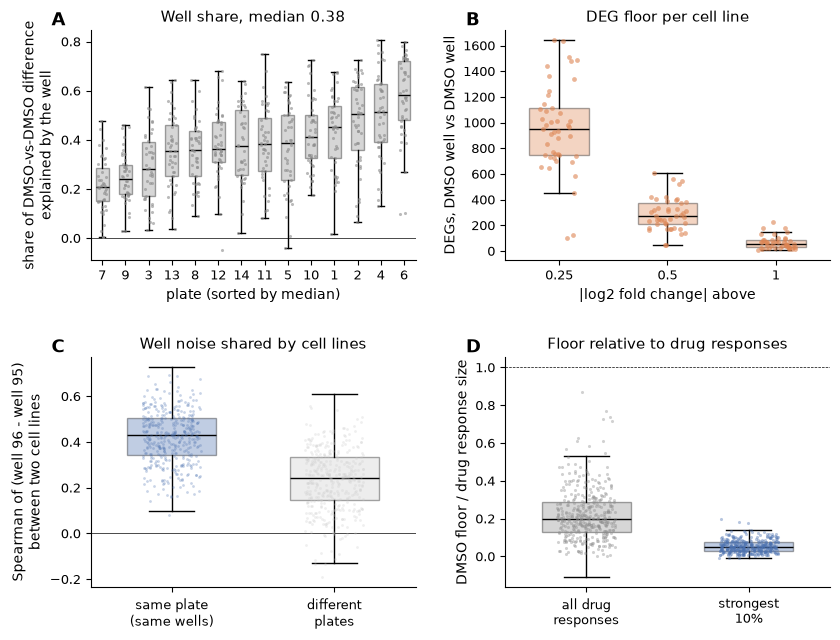

saved figures/FigS8_tahoe


In [12]:
# Figure S8: same style as the paper figures (make_figures.ipynb). Reads only the csv files in cache/.
import os, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
mpl.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
                     "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42, "font.family": "sans-serif"})
GREY, ORANGE, BLUE, LIGHT = "#8C8C8C", "#DD8452", "#4C72B0", "#CCCCCC"
C = "cache"; os.makedirs("figures", exist_ok=True)
rd = lambda f: pd.read_csv(f"{C}/{f}") if os.path.exists(f"{C}/{f}") else None
def letter(ax, s): ax.text(-0.12, 1.08, s, transform=ax.transAxes, fontsize=13, fontweight="bold", va="top")
def missing(ax, what): ax.axis("off"); ax.text(0.5, 0.5, f"missing: {what}", ha="center", va="center", fontsize=9, color="red")
def box_points(a, groups, colors, labels, rng, s=6, alpha=0.6, max_pts=400):
    bp = a.boxplot(groups, widths=0.55, showfliers=False, patch_artist=True, tick_labels=labels,
                   medianprops=dict(color="k", lw=1))
    for p, c in zip(bp["boxes"], colors): p.set_facecolor(c); p.set_alpha(0.35)
    for i, (g, c) in enumerate(zip(groups, colors), 1):
        g = np.asarray(g); g = g if len(g) <= max_pts else rng.choice(g, max_pts, replace=False)
        a.scatter(i + rng.uniform(-0.18, 0.18, len(g)), g, s=s, color=c, alpha=alpha, lw=0, zorder=3)
rng = np.random.default_rng(0)
SHARE, DEG, NOISE, CTX = rd("tahoe_well_share.csv"), rd("tahoe_dmso_vs_dmso_deg.csv"), rd("tahoe_shared_noise.csv"), rd("tahoe_floor_vs_drugs.csv")

fig, ax = plt.subplots(2, 2, figsize=(8.5, 6.5)); ax = ax.ravel()
#fig, ax = plt.subplots(2, 2, figsize=(11, 8)); ax = ax.ravel()
a = ax[0]; letter(a, "A")
if SHARE is None: missing(a, "tahoe_well_share.csv")
else:
    order = SHARE.groupby("plate").share.median().sort_values().index
    box_points(a, [SHARE[SHARE.plate == p].share for p in order], [GREY] * len(order),
               [p.replace("plate", "") for p in order], rng, s=5)
    a.axhline(0, color="k", lw=0.5); a.set_xlabel("plate (sorted by median)")
    a.set_ylabel("share of DMSO-vs-DMSO difference\nexplained by the well")
    a.set_title(f"Well share, median {SHARE.share.median():.2f}")
a = ax[1]; letter(a, "B")
if DEG is None: missing(a, "tahoe_dmso_vs_dmso_deg.csv")
else:
    box_points(a, [DEG.deg_025, DEG.deg_05, DEG.deg_1], [ORANGE] * 3, ["0.25", "0.5", "1"], rng, s=12)
    a.set_xlabel("|log2 fold change| above"); a.set_ylabel("DEGs, DMSO well vs DMSO well")
    a.set_title("DEG floor per cell line")
a = ax[2]; letter(a, "C")
if NOISE is None: missing(a, "tahoe_shared_noise.csv")
else:
    g = [NOISE[NOISE.comparison == k].spearman for k in ("same plate", "different plates")]
    box_points(a, g, [BLUE, LIGHT], ["same plate\n(same wells)", "different\nplates"], rng, s=4, alpha=0.3)
    a.axhline(0, color="k", lw=0.5); a.set_ylabel("Spearman of (well 96 - well 95)\nbetween two cell lines")
    a.set_title("Well noise shared by cell lines")
a = ax[3]; letter(a, "D")
if CTX is None: missing(a, "tahoe_floor_vs_drugs.csv (section 6)")
else:
    r = (CTX.floor / CTX.drug_size).clip(upper=2); strong = CTX.drug_size >= CTX.drug_size.quantile(0.9)
    box_points(a, [r, r[strong]], [GREY, BLUE], ["all drug\nresponses", "strongest\n10%"], rng, s=5, alpha=0.4)
    a.axhline(1, color="k", lw=0.5, ls="--"); a.set_ylabel("DMSO floor / drug response size")
    a.set_title("Floor relative to drug responses")
plt.tight_layout(h_pad=2.5, w_pad=2)
fig.savefig("figures/FigS8_tahoe.pdf", bbox_inches="tight"); fig.savefig("figures/FigS8_tahoe.png", dpi=300, bbox_inches="tight")
plt.show(); print("saved figures/FigS8_tahoe")

In [11]:
print(ROWS.groupby("plates").agg(n_sig=("p", lambda p: (p < 0.05).sum()), n=("p", "size")).to_string())

               n_sig   n
plates                  
plate1-plate4     42  46
plate2-plate4      7  46
plate3-plate4      1  44
